# Model evaluation: cross-validation and test

This notebook only reads what `Pipeline and Training.ipynb` already saved:

- `results/los_learning_curve/results/results_<algo>.csv` - CV and test metrics per algorithm and random state
- `results/los_learning_curve/shared/test_split_rs<rs>.joblib` - the train_val / test split for each random state
- `results/los_learning_curve/predictions/*_predictions.csv` - saved test-set predictions

Outputs (in `figures/`):

1. `model_comparison_cv_rmse_mae_baselines.png` – CV RMSE and CV MAE (mean ± std across 3 random states) for every model, with mean and median baselines computed **on the exact same CV folds**
2. `xgb_true_vs_pred.png` – true vs. predicted LOS for the selected model (XGB) and residuals by LOS range

In [10]:
import os
import glob

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

## Config

In [11]:
DATA_PATH = "../data/processed/sparcs_2024_final.parquet"
OUTPUT_DIR = "../results/los_learning_curve"
SPLIT_DIR = os.path.join(OUTPUT_DIR, "shared")
RESULT_DIR = os.path.join(OUTPUT_DIR, "results")
PREDICTION_DIR = os.path.join(OUTPUT_DIR, "predictions")
FIG_DIR = "../figures"

TARGET = "los"
PCT = 0.025              # the training percentage every algorithm was run at
N_FOLDS = 5
RANDOM_STATE = 42
N_STATES = 3
RANDOM_STATES = [RANDOM_STATE * i for i in range(1, N_STATES + 1)]  # 42, 84, 126
LOS_BINS = [0, 1, 2, 3, 5, 7, 14, 30, 120]

ALGORITHMS = ["elastic", "ridge", "xgb", "rf", "svr", "lightgbm", "knn"]
BEST_CONFIG = "xgb"

# same row order as the training notebook (read_parquet + reset_index)
y = pd.read_parquet(DATA_PATH, columns=[TARGET])[TARGET].reset_index(drop=True)
print(f"{len(y):,} stays | mean LOS {y.mean():.2f} | median LOS {y.median():.0f} | max {y.max()}")

1,993,483 stays | mean LOS 6.04 | median LOS 3 | max 120


Helper functions copied **verbatim** from `Pipeline and Training.ipynb`, so the 2.5% training subset is rebuilt row-for-row.

In [12]:
def get_los_bins(y):
    #Assign LOS observations to stratification bins.
    bins = pd.cut(y, bins=LOS_BINS, labels=False, include_lowest=True)
    if bins.isna().any():
        raise ValueError(
            "Some LOS values fall outside LOS_BINS. "
            "Check the target range and bin boundaries."
        )

    return bins


def create_subset(y_train_val, pct, random_state=RANDOM_STATE):
    #Create a nested, stratified subset of train_val.
    rng = np.random.default_rng(random_state)
    train_bins = get_los_bins(y_train_val).to_numpy()
    selected = []
    for bin_label in np.unique(train_bins):
        idx = np.where(train_bins == bin_label)[0]
        shuffled_idx = rng.permutation(idx)
        n_select = max(1, int(round(len(idx) * pct)))
        selected.extend(shuffled_idx[:n_select])

    return np.array(selected, dtype=int)


def pstd(s):
    # population std (ddof=0), the same convention as the teammates' CV RMSE chart
    return np.std(s, ddof=0)

## 1. Load the saved model results

In [13]:
results = pd.concat(
    [pd.read_csv(os.path.join(RESULT_DIR, f"results_{a}.csv")) for a in ALGORITHMS],
    ignore_index=True,
)
results["config"] = results["algorithm"] + np.where(
    results["use_interactions"].astype(str) == "True", " + interactions", ""
)

final = results[
    np.isclose(results["pct"].astype(float), PCT) & results["random_state"].isin(RANDOM_STATES)
].copy()

# every configuration should have all 3 random states
print(final.groupby("config")["random_state"].nunique().to_string())

config
elastic                   3
elastic + interactions    3
knn                       3
lightgbm                  3
rf                        3
ridge                     3
ridge + interactions      3
svr                       3
xgb                       3


In [14]:
model_cv = (
    final.groupby("config")
    .agg(cv_rmse_mean=("cv_rmse", "mean"), cv_rmse_std=("cv_rmse", pstd),
         cv_mae_mean=("cv_mae", "mean"), cv_mae_std=("cv_mae", pstd),
         cv_r2_mean=("cv_r2", "mean"), cv_r2_std=("cv_r2", pstd))
    .sort_values("cv_rmse_mean")
)
model_cv.round(4)

,cv_rmse_mean,cv_rmse_std,cv_mae_mean,cv_mae_std,cv_r2_mean,cv_r2_std
config,,,,,,
xgb,8.5101,0.1422,4.4277,0.0340,0.0673,0.0030
ridge + interactions,8.5224,0.1430,4.4700,0.0321,0.0647,0.0018
elastic + interactions,8.5235,0.1412,4.4635,0.0312,0.0645,0.0013
lightgbm,8.5272,0.1292,4.4247,0.0304,0.0637,0.0047
ridge,8.5274,0.1436,4.4774,0.0313,0.0636,0.0018
elastic,8.5304,0.1418,4.4723,0.0310,0.0630,0.0013
rf,8.6029,0.1483,4.4740,0.0367,0.0468,0.0028
knn,8.6689,0.1378,4.4825,0.0315,0.0323,0.0031
svr,8.8012,0.1389,3.8978,0.0228,0.0026,0.0037


## 2. Baselines on the exact same CV folds

For each random state we rebuild what the models saw:

1. load the saved train_val/test split,
2. rebuild the stratified 2.5% training subset with `create_subset`,
3. split it with `KFold(5, shuffle=True, random_state=rs)` – the same object `GridSearchCV` / the early-stopping loop used.

In every fold the baseline "model" predicts one constant for the whole validation fold: the **mean** or the **median** LOS of the training folds. The mean minimises squared error (RMSE), the median minimises absolute error (MAE), so each baseline is the strongest constant predictor for one of the two metrics.

Fold scores are averaged (like `mean_test_*` in `GridSearchCV`), then we take mean ± std across the 3 random states, exactly as for the models.

We also score the baselines on each random state's **test set**, fitting the constant on that state's 2.5% training subset (the same data the models were trained on).

In [15]:
def constant_scores(y_fit, y_eval):
    # Score the mean and median of y_fit as constant predictions for y_eval
    rows = []
    for name, value in [("mean", y_fit.mean()), ("median", y_fit.median())]:
        pred = np.full(len(y_eval), value, dtype=float)
        rows.append({
            "baseline": name,
            "constant": value,
            "rmse": root_mean_squared_error(y_eval, pred),
            "mae": mean_absolute_error(y_eval, pred),
            "r2": r2_score(y_eval, pred),
        })
    return rows


n_train_saved = final.groupby("random_state")["n_train"].first()

cv_rows, test_rows = [], []
for rs in RANDOM_STATES:
    split = joblib.load(os.path.join(SPLIT_DIR, f"test_split_rs{rs}.joblib"))
    y_train_val = y.iloc[split["train_idx"]]
    y_test = y.iloc[split["test_idx"]]

    subset_idx = create_subset(y_train_val, PCT, random_state=rs)
    y_train = y_train_val.iloc[subset_idx]
    assert len(y_train) == n_train_saved[rs], "Rebuilt subset does not match the saved n_train"

    kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=rs)
    for fold, (tr, va) in enumerate(kf.split(y_train)):
        for row in constant_scores(y_train.iloc[tr], y_train.iloc[va]):
            cv_rows.append({"random_state": rs, "fold": fold, **row})

    for row in constant_scores(y_train, y_test):
        test_rows.append({"random_state": rs, **row})

    print(f"rs {rs:>3}: train subset {len(y_train):,} rows (matches saved n_train) | test {len(y_test):,} rows")

baseline_cv_folds = pd.DataFrame(cv_rows)
baseline_test = pd.DataFrame(test_rows)

rs  42: train subset 49,587 rows (matches saved n_train) | test 9,968 rows
rs  84: train subset 49,587 rows (matches saved n_train) | test 9,968 rows
rs 126: train subset 49,587 rows (matches saved n_train) | test 9,968 rows


In [16]:
# average over folds within a random state, then mean +/- std across random states
baseline_cv_state = baseline_cv_folds.groupby(["baseline", "random_state"])[["rmse", "mae", "r2"]].mean()

baseline_cv = baseline_cv_state.groupby("baseline").agg(
    rmse_mean=("rmse", "mean"), rmse_std=("rmse", pstd),
    mae_mean=("mae", "mean"), mae_std=("mae", pstd),
    r2_mean=("r2", "mean"), r2_std=("r2", pstd),
)
baseline_cv.round(4)

,rmse_mean,rmse_std,mae_mean,mae_std,r2_mean,r2_std
baseline,,,,,,
mean,8.8134,0.1418,4.7269,0.0297,-0.0001,0.0000
median,9.3200,0.1401,4.1003,0.0205,-0.1186,0.0025


## 3. Figure: CV RMSE for every model vs. the baselines

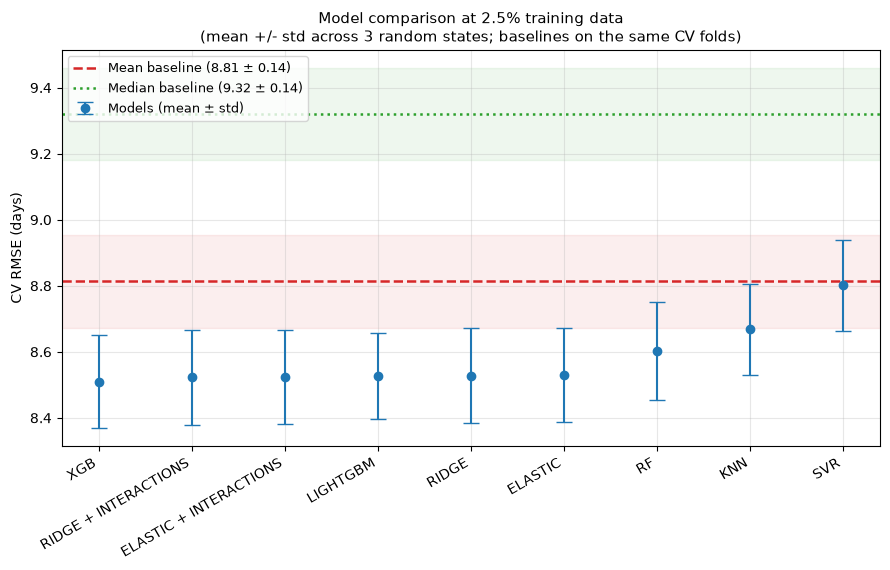

In [24]:
order = model_cv.index
x = np.arange(len(order))

BASELINE_STYLE = {
    "mean": {"color": "tab:red", "ls": "--"},
    "median": {"color": "tab:green", "ls": ":"},
}

fig, ax = plt.subplots(figsize=(9, 5.8))

ax.errorbar(x, model_cv["cv_rmse_mean"], yerr=model_cv["cv_rmse_std"],
            fmt="o", capsize=6, color="tab:blue", label="Models (mean ± std)")

for name, style in BASELINE_STYLE.items():
    m = baseline_cv.loc[name, "rmse_mean"]
    s = baseline_cv.loc[name, "rmse_std"]
    ax.axhline(m, lw=1.8, label=f"{name.capitalize()} baseline ({m:.2f} ± {s:.2f})", **style)
    ax.axhspan(m - s, m + s, color=style["color"], alpha=0.08)

ax.set_xticks(x)
ax.set_xticklabels(order.str.upper(), rotation=30, ha="right")
ax.set_ylabel("CV RMSE (days)")
ax.set_title(f"Model comparison at {PCT:.1%} training data\n"
             f"(mean +/- std across {len(RANDOM_STATES)} random states; baselines on the same CV folds)",
             fontsize=11)
ax.grid(alpha=0.3)
ax.legend(fontsize=9, loc="upper left")

fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "model_comparison_cv_rmse_baselines.png"), dpi=300, bbox_inches="tight")
plt.show()

## 4. Figure: Test scores vs. baselines

In [18]:
model_test = final[["random_state", "config", "test_rmse", "test_mae", "test_r2"]].rename(
    columns={"test_rmse": "rmse", "test_mae": "mae", "test_r2": "r2"}
)
base_test_long = baseline_test.assign(config=baseline_test["baseline"] + " baseline")[
    ["random_state", "config", "rmse", "mae", "r2"]
]
test_long = pd.concat([model_test, base_test_long], ignore_index=True)

test_summary = (
    test_long.groupby("config")
    .agg(test_rmse_mean=("rmse", "mean"), test_rmse_std=("rmse", pstd),
         test_mae_mean=("mae", "mean"), test_mae_std=("mae", pstd),
         test_r2_mean=("r2", "mean"), test_r2_std=("r2", pstd))
    .sort_values("test_rmse_mean")
)
test_summary.round(4)

,test_rmse_mean,test_rmse_std,test_mae_mean,test_mae_std,test_r2_mean,test_r2_std
config,,,,,,
xgb,8.5946,0.1551,4.4456,0.0340,0.0716,0.0087
ridge + interactions,8.6018,0.1680,4.4860,0.0324,0.0701,0.0056
elastic + interactions,8.6054,0.1719,4.4812,0.0331,0.0693,0.0048
ridge,8.6115,0.1701,4.4951,0.0311,0.0680,0.0049
elastic,8.6161,0.1736,4.4912,0.0310,0.0670,0.0042
lightgbm,8.6247,0.1550,4.4439,0.0467,0.0651,0.0072
rf,8.6886,0.1625,4.4888,0.0338,0.0512,0.0044
knn,8.7500,0.1649,4.4945,0.0471,0.0378,0.0040
svr,8.8860,0.1807,3.9127,0.0471,0.0077,0.0057


KeyError: 'cv_rmse_mean'

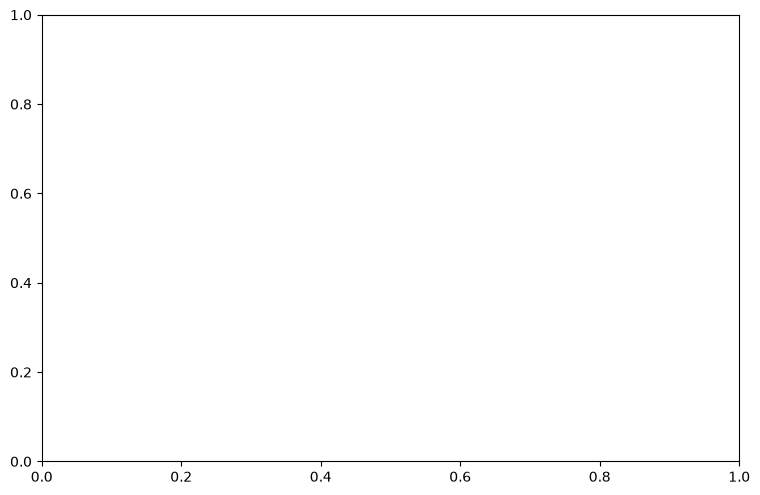

In [ ]:
order = test_summary.index
x = np.arange(len(order))

BASELINE_STYLE = {
    "mean": {"color": "tab:red", "ls": "--"},
    "median": {"color": "tab:green", "ls": ":"},
}

fig, ax = plt.subplots(figsize=(9, 5.8))

ax.errorbar(x, test_summary["test_rmse_mean"], yerr=test_summary["test_rmse_std"],
            fmt="o", capsize=6, color="tab:blue", label="Models (mean +/- std)")

for name, style in BASELINE_STYLE.items():
    m = baseline_cv.loc[name, "rmse_mean"]
    s = baseline_cv.loc[name, "rmse_std"]
    ax.axhline(m, lw=1.8, label=f"{name.capitalize()} baseline ({m:.2f} ± {s:.2f})", **style)
    ax.axhspan(m - s, m + s, color=style["color"], alpha=0.08)

ax.set_xticks(x)
ax.set_xticklabels(order.str.upper(), rotation=30, ha="right")
ax.set_ylabel("CV RMSE (days)")
ax.set_title(f"Model comparison at {PCT:.1%} training data\n"
             f"(mean +/- std across {len(RANDOM_STATES)} random states; baselines on other train folds)",
             fontsize=11)
ax.grid(alpha=0.3)
ax.legend(fontsize=9, loc="upper left")

fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "model_comparison_cv_rmse_baselines.png"), dpi=300, bbox_inches="tight")
plt.show()

### Paired comparison (same random state = same split, same test rows)

The error bars above are wide because some test splits are simply harder than others, and that difficulty is **shared** by every model on that split. Comparing two models *within* each random state removes that shared noise, which is the fair way to judge whether a gap is real. Negative = XGB has lower error.

In [19]:
PAIRS = {
    "XGB - mean baseline": (BEST_CONFIG, "mean baseline"),
    "XGB - median baseline": (BEST_CONFIG, "median baseline"),
    "XGB - ridge + interactions": (BEST_CONFIG, "ridge + interactions"),
}


def paired_differences(long_df, pairs, metrics=("rmse", "mae")):
    rows = []
    for metric in metrics:
        wide = long_df.pivot_table(index="random_state", columns="config", values=metric)
        for label, (a, b) in pairs.items():
            diff = wide[a] - wide[b]
            rel = 100 * diff / wide[b]
            rows.append({
                "metric": metric.upper(), "comparison": label,
                **{f"rs{rs}": d for rs, d in diff.items()},
                "mean_diff": diff.mean(), "std_diff": pstd(diff),
                "mean_rel_%": rel.mean(),
            })
    return pd.DataFrame(rows).set_index(["metric", "comparison"])


print("TEST set: XGB minus comparison (days)")
paired_differences(test_long, PAIRS).round(3)

TEST set: XGB minus comparison (days)


rs42   rs84  rs126  mean_diff  std_diff  \
metric comparison                                                             
RMSE   XGB - mean baseline        -0.266 -0.375 -0.338     -0.326     0.045   
       XGB - median baseline      -0.773 -0.884 -0.844     -0.834     0.046   
       XGB - ridge + interactions  0.012 -0.027 -0.006     -0.007     0.016   
MAE    XGB - mean baseline        -0.285 -0.312 -0.325     -0.307     0.016   
       XGB - median baseline       0.352  0.315  0.306      0.324     0.020   
       XGB - ridge + interactions -0.023 -0.046 -0.053     -0.040     0.013   

                                   mean_rel_%  
metric comparison                              
RMSE   XGB - mean baseline             -3.649  
       XGB - median baseline           -8.839  
       XGB - ridge + interactions      -0.081  
MAE    XGB - mean baseline             -6.465  
       XGB - median baseline            7.867  
       XGB - ridge + interactions      -0.900

In [20]:
# same idea on the CV scores
cv_long = pd.concat([
    final[["random_state", "config", "cv_rmse", "cv_mae"]].rename(columns={"cv_rmse": "rmse", "cv_mae": "mae"}),
    baseline_cv_state.reset_index().assign(config=lambda d: d["baseline"] + " baseline")[
        ["random_state", "config", "rmse", "mae"]],
], ignore_index=True)

print("CV: XGB minus comparison (days)")
paired_differences(cv_long, PAIRS).round(3)

CV: XGB minus comparison (days)


rs42   rs84  rs126  mean_diff  std_diff  \
metric comparison                                                             
RMSE   XGB - mean baseline        -0.290 -0.299 -0.321     -0.303     0.013   
       XGB - median baseline      -0.797 -0.809 -0.824     -0.810     0.011   
       XGB - ridge + interactions  0.006 -0.005 -0.038     -0.012     0.019   
MAE    XGB - mean baseline        -0.287 -0.297 -0.313     -0.299     0.011   
       XGB - median baseline       0.348  0.316  0.318      0.327     0.015   
       XGB - ridge + interactions -0.034 -0.038 -0.055     -0.042     0.009   

                                   mean_rel_%  
metric comparison                              
RMSE   XGB - mean baseline             -3.442  
       XGB - median baseline           -8.693  
       XGB - ridge + interactions      -0.143  
MAE    XGB - mean baseline             -6.329  
       XGB - median baseline            7.984  
       XGB - ridge + interactions      -0.946

## 5. True vs. predicted LOS for the selected model (XGB)

Built from the saved test predictions of all 3 random states (≈ 30k test stays). LOS is very right-skewed, so the hexbin uses log axes and log counts.

In [21]:
pred_files = sorted(glob.glob(os.path.join(
    PREDICTION_DIR, f"{BEST_CONFIG}_pct_{PCT:g}_no_interactions_rs*_predictions.csv")))
assert len(pred_files) == len(RANDOM_STATES), pred_files

preds = pd.concat(
    [pd.read_csv(f).assign(random_state=int(f.split("_rs")[-1].split("_")[0])) for f in pred_files],
    ignore_index=True,
)

BIN_LABELS = ["1", "2", "3", "4-5", "6-7", "8-14", "15-30", "31-120"]
preds["los_bin"] = pd.cut(preds["y_true"], bins=LOS_BINS, labels=BIN_LABELS, include_lowest=True)

print(f"{len(preds):,} test predictions | predicted LOS range "
      f"{preds['y_pred'].min():.2f} - {preds['y_pred'].max():.2f} days | true LOS range "
      f"{preds['y_true'].min()} - {preds['y_true'].max()} days")

by_bin = preds.groupby("los_bin", observed=True).agg(
    n=("y_true", "size"), mean_true=("y_true", "mean"), mean_pred=("y_pred", "mean"),
    mean_residual=("residual", "mean"), mae=("absolute_error", "mean"))
by_bin.round(2)

29,904 test predictions | predicted LOS range 0.50 - 80.06 days | true LOS range 1 - 120 days


,n,mean_true,mean_pred,mean_residual,mae
los_bin,,,,,
1,5289,1.00,5.49,-4.49,4.49
2,5406,2.00,5.34,-3.34,3.36
3,4515,3.00,5.61,-2.61,2.71
4-5,5289,4.40,6.05,-1.64,1.90
6-7,2958,6.44,6.47,-0.02,1.23
8-14,4017,10.29,6.81,3.48,3.92
15-30,1860,20.07,7.37,12.70,12.85
31-120,570,53.19,8.65,44.54,44.73


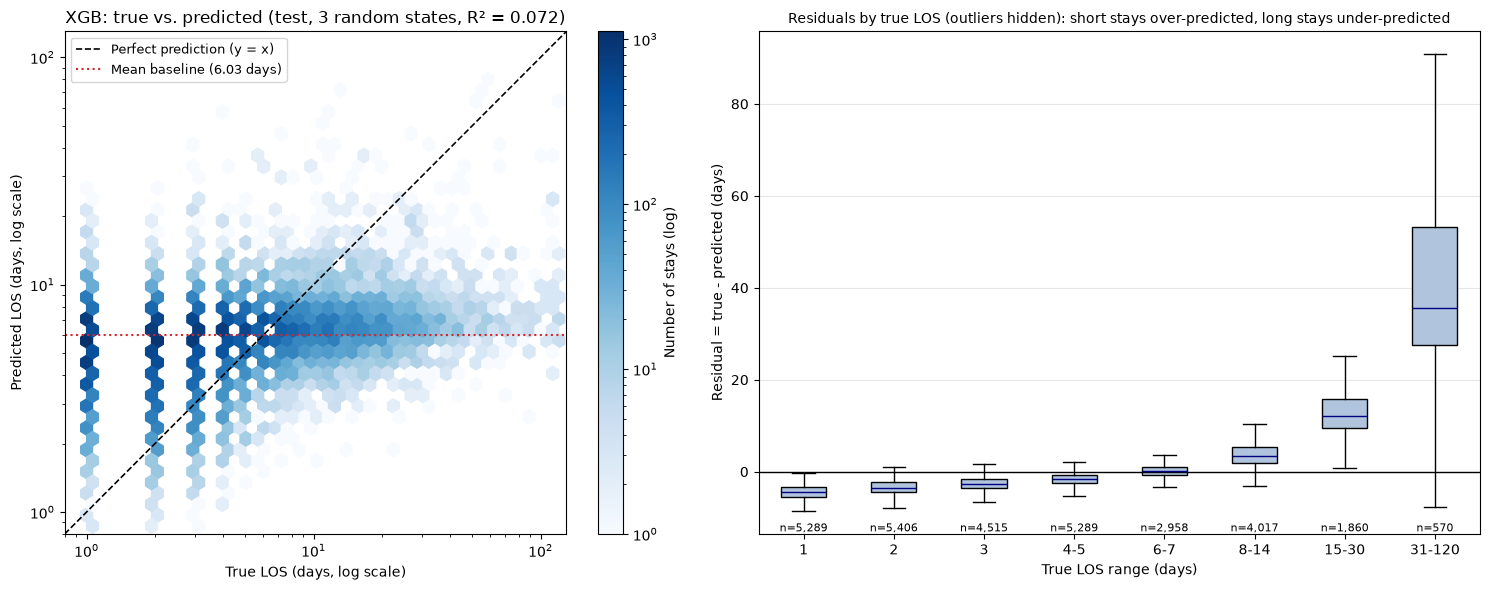

In [22]:
mean_baseline_value = baseline_test.loc[baseline_test["baseline"] == "mean", "constant"].mean()
r2_all = r2_score(preds["y_true"], preds["y_pred"])

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 1.15]})

# left: hexbin of true vs predicted
ax = axes[0]
hb = ax.hexbin(preds["y_true"], preds["y_pred"].clip(lower=0.5), gridsize=40,
               xscale="log", yscale="log", bins="log", cmap="Blues", mincnt=1)
lims = [0.8, 130]
ax.plot(lims, lims, "k--", lw=1.2, label="Perfect prediction (y = x)")
ax.axhline(mean_baseline_value, color="tab:red", ls=":", lw=1.5,
           label=f"Mean baseline ({mean_baseline_value:.2f} days)")
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("True LOS (days, log scale)")
ax.set_ylabel("Predicted LOS (days, log scale)")
ax.set_title(f"XGB: true vs. predicted (test, 3 random states, R² = {r2_all:.3f})")
ax.legend(loc="upper left", fontsize=9)
fig.colorbar(hb, ax=ax, label="Number of stays (log)")

# right: residuals by true LOS range
ax = axes[1]
groups = [preds.loc[preds["los_bin"] == b, "residual"] for b in BIN_LABELS]
ax.boxplot(groups, tick_labels=BIN_LABELS, showfliers=False, patch_artist=True,
           boxprops={"facecolor": "lightsteelblue"}, medianprops={"color": "navy"})
ax.axhline(0, color="k", lw=1)
for i, b in enumerate(BIN_LABELS, start=1):
    ax.text(i, ax.get_ylim()[0], f"n={by_bin.loc[b, 'n']:,}", ha="center", va="bottom", fontsize=8)
ax.set_xlabel("True LOS range (days)")
ax.set_ylabel("Residual = true - predicted (days)")
ax.set_title("Residuals by true LOS (outliers hidden): short stays over-predicted, long stays under-predicted")
ax.title.set_fontsize(10)
ax.grid(alpha=0.3, axis="y")

fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "xgb_true_vs_pred.png"), dpi=300, bbox_inches="tight")
plt.show()

## 6. Takeaways for the Results slide

Check these against the printed numbers above before using them.

- **Most predictive model:** XGB has the lowest mean CV RMSE and was best in 2 of 3 random states. The top six configurations (XGB, Ridge/ElasticNet ± interactions, LightGBM) are within about 0.02 days of each other, far less than the across-split std (about 0.14). They are effectively tied, and XGB is chosen by the pre-registered rule (lowest mean CV RMSE). RF, KNN and SVR are clearly worse on RMSE.
- **Versus the baseline (RMSE):** XGB beats the mean baseline by about 0.3 days of RMSE (about 4%) and does so in **every** random state (see the paired table). So the improvement is consistent, but small in absolute terms. R² of about 0.07 means admission-time features explain only a small share of the variation in LOS.
- **MAE tells a different story:** the median baseline (always predict 3 days) has a lower MAE than XGB. Models trained to minimise squared error chase the long-stay tail and over-predict the many short stays. SVR (epsilon-insensitive loss, closer to a median predictor) has the best MAE of all models but almost zero R². Which model is "best" depends on whether large misses on long stays (RMSE) or typical-patient error (MAE) matters more.
- **True vs. predicted:** predictions are compressed into a narrow band of about 3–10 days. Short stays are over-predicted and long stays (>14 days, about 8% of stays) are heavily under-predicted. The model can rank risk somewhat but cannot reproduce the long tail from admission information alone.